# Cheltenham Analysis

# Data Locations

This Jupyter notebook is in "OneDrive - Turftrax\Documents - Tech Support\Processes\000020-data_science_analysis\010-cheltenham_2024".

In [2]:
# import modules and settings

import pandas as pd
import numpy as np
import pymysql.cursors
import warnings
import os
import datetime
import seaborn as sns
import matplotlib.pyplot as plt

#ignore warnings
warnings.filterwarnings("ignore")

# graph setting
sns.set_style("whitegrid")

# jcr courses
jcr_courses = ["Aintree", "Carlisle", "Cheltenham", "Epsom Downs", "Exeter", "Haydock Park", "Huntingdon", "Kempton Park", "Market Rasen", "Newmarket", "Nottingham", "Sandown Park", "Warwick", "Wincanton"]

In [3]:
# set up functions

# database connection and data download

def fetch_data(sql_query):
        
    # establish a connection to the MySQL database
    connection = pymysql.connect(
        host="tthubdb-cluster-1.cluster-che9ka0taxng.eu-west-1.rds.amazonaws.com",
        user="hubview",
        password="v13whub_",
        database="ttmaps"
    )

    try:        
        # check the connection status
        connection.ping()

        # if the ping is successful, the connection is still active
        print("Database connection is active")
    
    except MySQLdb.Error as e:
        # If an error occurs, the connection is closed or lost
        print(f"Error: {e}")

    # Execute the SQL query
    try:    
        with connection.cursor() as cursor:
            cursor.execute(sql_query)

            # Get the field names from the cursor description
            field_names = [i[0] for i in cursor.description]
            # Fetch all data and return as a DataFrame
            return pd.DataFrame(cursor.fetchall(), columns=field_names)

    finally:
        # always close the database connection
        connection.close()


In [9]:
# download data
sql_query = " SELECT * FROM ttmaps.pageview as ttp WHERE YEAR(ttp.viewdate) = 2024 AND ttp.pagetype <> ''"
df_webstats = fetch_data(sql_query)

# ensure viewdate has the correct datatype
df_webstats['viewdate'] = pd.to_datetime(df_webstats['viewdate'])

# convert pagename and pagetype to lowercase
df_webstats['pagename'] = df_webstats['pagename'].str.lower()
df_webstats['pagetype'] = df_webstats['pagetype'].str.lower()
print(df_webstats.info())
print(df_webstats.head())

Database connection is active
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 524733 entries, 0 to 524732
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         524733 non-null  int64         
 1   viewdate   524733 non-null  datetime64[ns]
 2   pagename   524733 non-null  object        
 3   pagetype   524733 non-null  object        
 4   sessionid  524733 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 20.0+ MB
None
         id   viewdate             pagename                   pagetype  \
0  17793490 2024-01-01             goingmap      exeter for 01/01/2024   
1  17793491 2024-01-01  latest going report                 cheltenham   
2  17793495 2024-01-01   goingstick archive                       york   
3  17793499 2024-01-01             goingmap  cheltenham for 01/01/2024   
4  17793501 2024-01-01  latest going report                 cheltenham   

   s

In [21]:
# filter all fields that contain any of the jcr courses in the pagename
pattern = '|'.join(jcr_courses).lower()
df_webstats_filtered = df_webstats[df_webstats['pagetype'].str.contains(pattern, na=False)]
df_webstats_filtered.reset_index(drop=True, inplace=True)

# add course, which is extracted from the pagetype field using the pattern
df_webstats_filtered['course'] = df_webstats_filtered['pagetype'].str.extract(f'({pattern})', expand=False).str.title()
df_webstats_filtered

,id,viewdate,pagename,pagetype,sessionid,course
0,17793490,2024-01-01,goingmap,exeter for 01/01/2024,156533600,Exeter
1,17793491,2024-01-01,latest going report,cheltenham,156533601,Cheltenham
2,17793499,2024-01-01,goingmap,cheltenham for 01/01/2024,156533619,Cheltenham
3,17793501,2024-01-01,latest going report,cheltenham,156533621,Cheltenham
4,17793968,2024-01-01,latest going report,cheltenham,156533917,Cheltenham
...,...,...,...,...,...,...
61987,18683241,2024-12-31,goingmap,cheltenham for 01/01/2025,407608895,Cheltenham
61988,18683248,2024-12-31,goingmap,cheltenham for 01/01/2025,407608913,Cheltenham
61989,18683249,2024-12-31,latest going report,cheltenham,407608914,Cheltenham
61990,18683252,2024-12-31,latest going report,cheltenham,407608923,Cheltenham


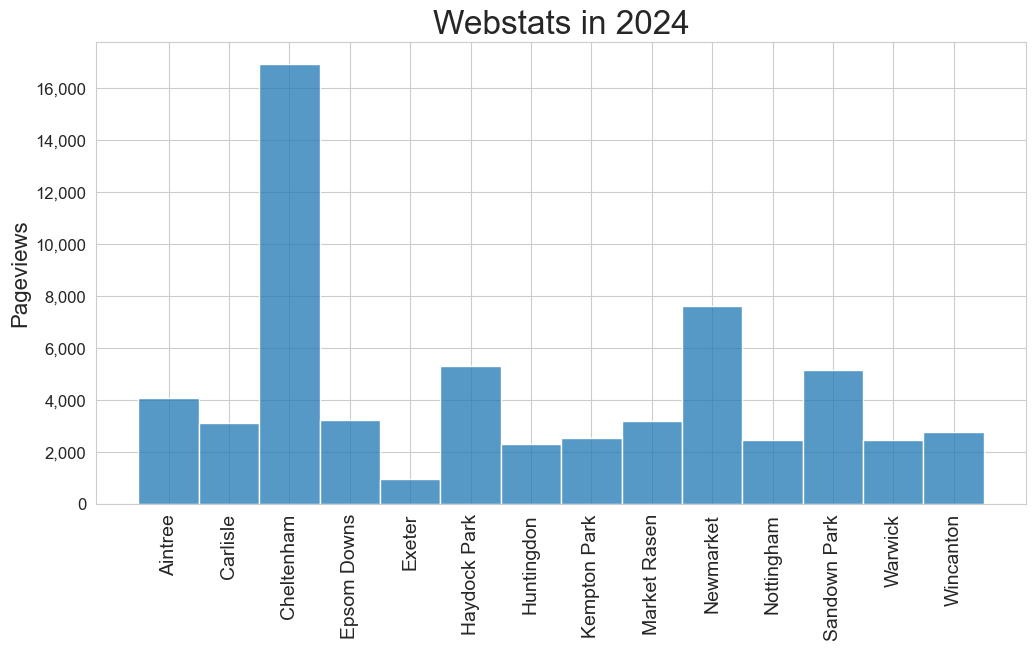

In [38]:
df_webstats_filtered['course'] = pd.Categorical(df_webstats_filtered['course'], 
                                                categories=jcr_courses, 
                                                ordered=True)


# plot webstats barchart
plt.figure(figsize=(12, 6))
sns.histplot(df_webstats_filtered['course'], bins=len(jcr_courses))
plt.gca().get_yaxis().set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.title('Webstats in 2024', fontsize=24)
plt.xlabel('', fontsize=12)
plt.ylabel('Pageviews', fontsize=16)

plt.xticks(fontsize=14, rotation=90)
plt.yticks(fontsize=12)

plt.show()

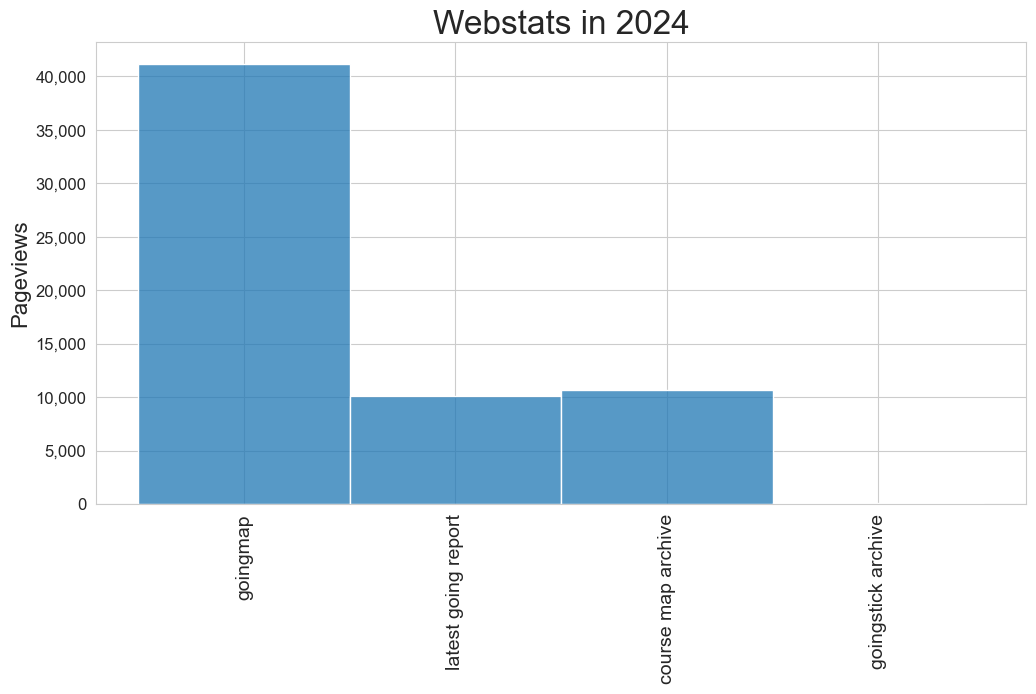

In [39]:
# plot webstats barchart
plt.figure(figsize=(12, 6))
sns.histplot(df_webstats_filtered['pagename'])
plt.gca().get_yaxis().set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.title('Webstats in 2024', fontsize=24)
plt.xlabel('', fontsize=12)
plt.ylabel('Pageviews', fontsize=16)

plt.xticks(fontsize=14, rotation=90)
plt.yticks(fontsize=12)

plt.show()

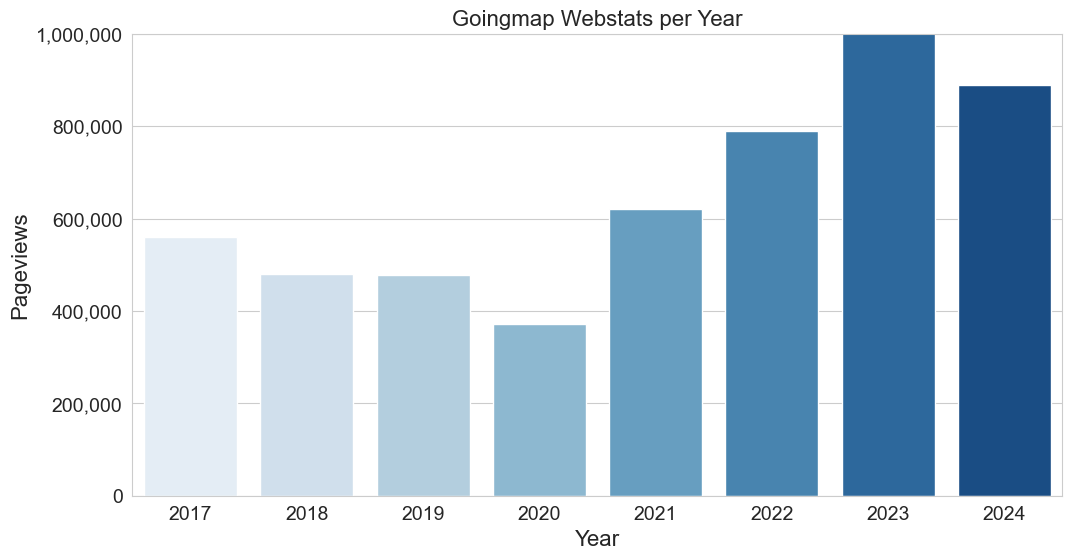

In [ ]:
# plot webstats barchart
plt.figure(figsize=(12, 6))
sns.barplot(x='year', y='views', data=df_webstats[df_webstats['year'] != 2025], palette='Blues')
plt.gca().get_yaxis().set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.title('Goingmap Webstats per Year', fontsize=16)
plt.xlabel('Year', fontsize=16)
plt.ylabel('Pageviews', fontsize=16)
plt.ylim(0, 1000000)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.show()